In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("winequality-red.csv")
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [3]:
print("Rows and Columns:", df.shape)

Rows and Columns: (1599, 12)


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [5]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [6]:
df.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [7]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 240


In [8]:
df = df.drop_duplicates().reset_index(drop=True)
print("Shape after cleaning:", df.shape)

Shape after cleaning: (1359, 12)


In [9]:
df["quality"].value_counts().sort_index()

quality
3     10
4     53
5    577
6    535
7    167
8     17
Name: count, dtype: int64

In [10]:
df["quality_label"] = (df["quality"] >= 6).astype(int)
df["quality_label"].value_counts()

quality_label
1    719
0    640
Name: count, dtype: int64

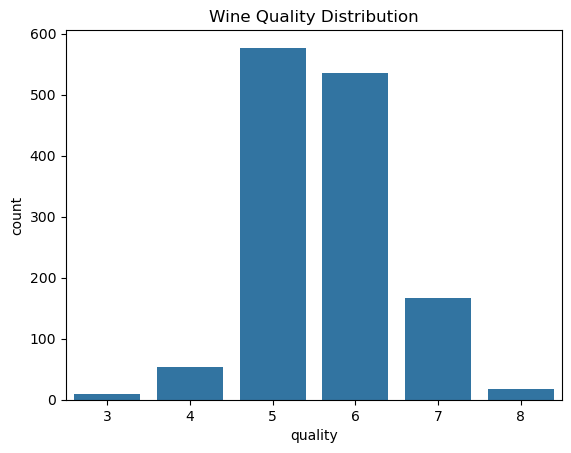

In [11]:
sns.countplot(data=df, x="quality")
plt.title("Wine Quality Distribution")
plt.show()

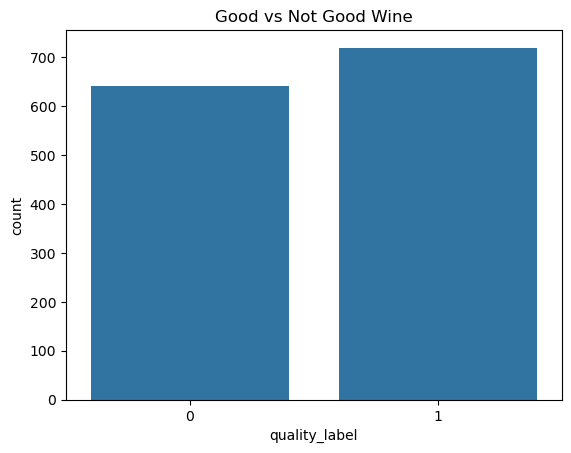

In [12]:
sns.countplot(data=df, x="quality_label")
plt.title("Good vs Not Good Wine")
plt.show()

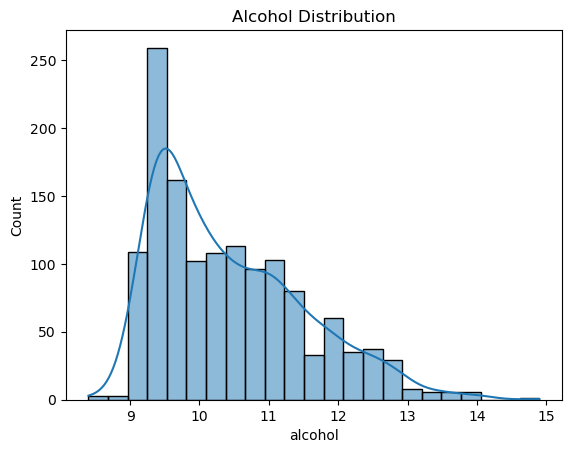

In [13]:
sns.histplot(df["alcohol"], kde=True)
plt.title("Alcohol Distribution")
plt.show()

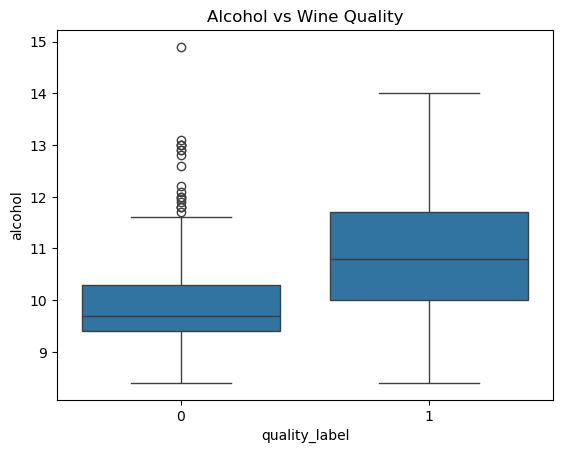

In [14]:
sns.boxplot(data=df, x="quality_label", y="alcohol")
plt.title("Alcohol vs Wine Quality")
plt.show()

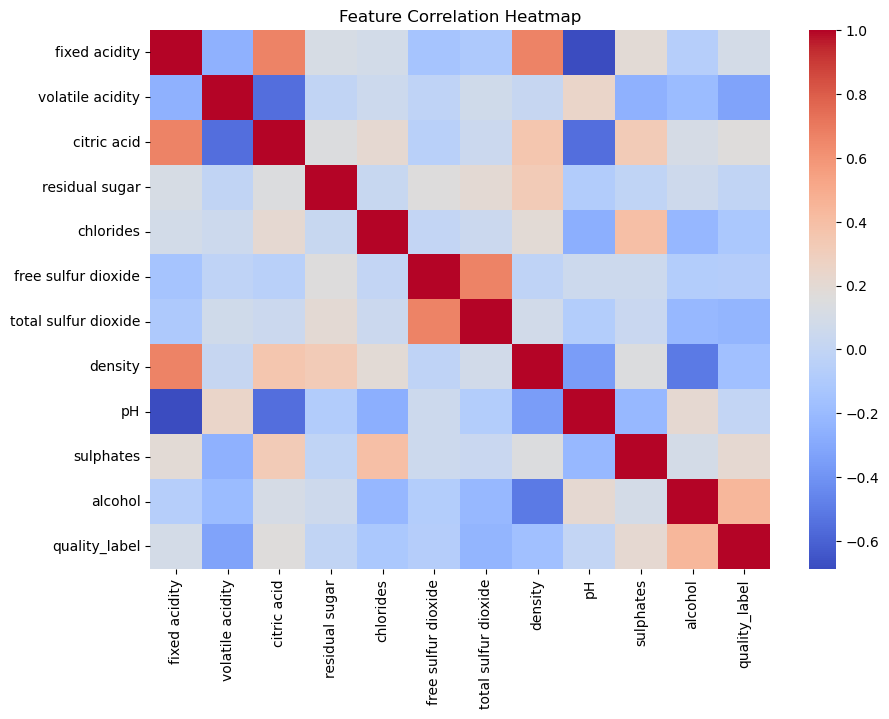

In [15]:
plt.figure(figsize=(10, 7))
sns.heatmap(df.drop(columns="quality").corr(), cmap="coolwarm")
plt.title("Feature Correlation Heatmap")
plt.show()

In [16]:
correlation = df.drop(columns="quality").corr()["quality_label"]
correlation.sort_values(ascending=False)

quality_label           1.000000
alcohol                 0.446176
sulphates               0.211365
citric acid             0.167903
fixed acidity           0.091761
pH                      0.004693
residual sugar         -0.002371
free sulfur dioxide    -0.069207
chlorides              -0.115071
density                -0.168958
total sulfur dioxide   -0.235046
volatile acidity       -0.327195
Name: quality_label, dtype: float64

In [17]:
X = df.drop(columns=["quality", "quality_label"])
y = df["quality_label"]

In [18]:
print("Features:", X.shape)
print("Target:", y.shape)
print("Feature Names:", X.columns.tolist())

Features: (1359, 11)
Target: (1359,)
Feature Names: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']


In [19]:
from sklearn.model_selection import train_test_split

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [21]:
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (1087, 11)
Testing Data: (272, 11)


In [22]:
from sklearn.ensemble import RandomForestClassifier

In [23]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [24]:
rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [25]:
rf_pred = rf.predict(X_test)

In [26]:
from sklearn.ensemble import AdaBoostClassifier

In [27]:
ada = AdaBoostClassifier(
    n_estimators=100,
    random_state=42
)

In [28]:
ada.fit(X_train, y_train)

AdaBoostClassifier(n_estimators=100, random_state=42)

In [29]:
ada_pred = ada.predict(X_test)

In [30]:
from sklearn.ensemble import GradientBoostingClassifier

In [31]:
gb = GradientBoostingClassifier(
    n_estimators=100,
    random_state=42
)

In [32]:
gb.fit(X_train, y_train)

GradientBoostingClassifier(random_state=42)

In [33]:
gb.fit(X_train, y_train)

GradientBoostingClassifier(random_state=42)

In [34]:
gb_pred = gb.predict(X_test)

In [35]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [36]:
print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.72      0.77      0.74       128
           1       0.78      0.74      0.76       144

    accuracy                           0.75       272
   macro avg       0.75      0.75      0.75       272
weighted avg       0.75      0.75      0.75       272



In [37]:
print(classification_report(y_test, ada_pred))

              precision    recall  f1-score   support

           0       0.72      0.73      0.72       128
           1       0.76      0.75      0.75       144

    accuracy                           0.74       272
   macro avg       0.74      0.74      0.74       272
weighted avg       0.74      0.74      0.74       272



In [38]:
print(classification_report(y_test, gb_pred))

              precision    recall  f1-score   support

           0       0.74      0.76      0.75       128
           1       0.78      0.76      0.77       144

    accuracy                           0.76       272
   macro avg       0.76      0.76      0.76       272
weighted avg       0.76      0.76      0.76       272



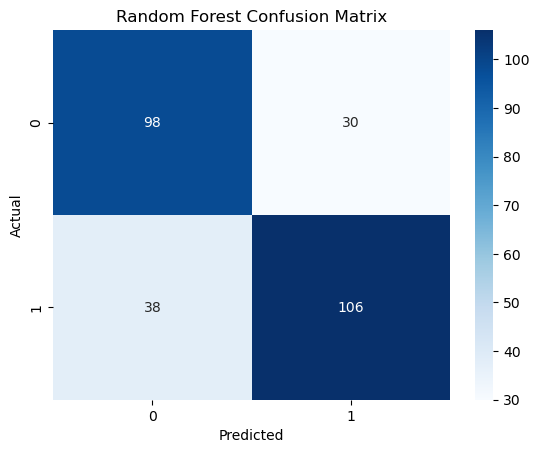

In [39]:
sns.heatmap(confusion_matrix(y_test, rf_pred),
            annot=True, fmt="d", cmap="Blues")
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

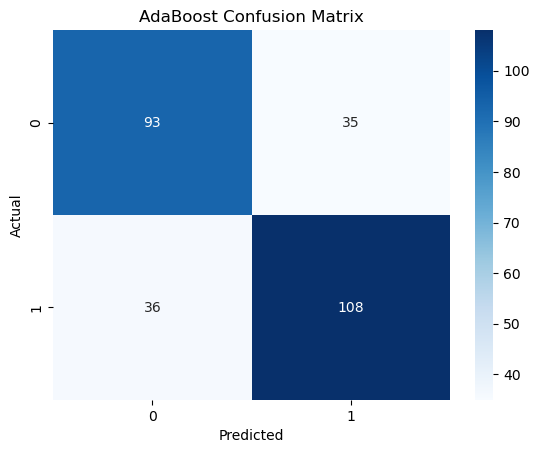

In [40]:
sns.heatmap(confusion_matrix(y_test, ada_pred),
            annot=True, fmt="d", cmap="Blues")
plt.title("AdaBoost Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

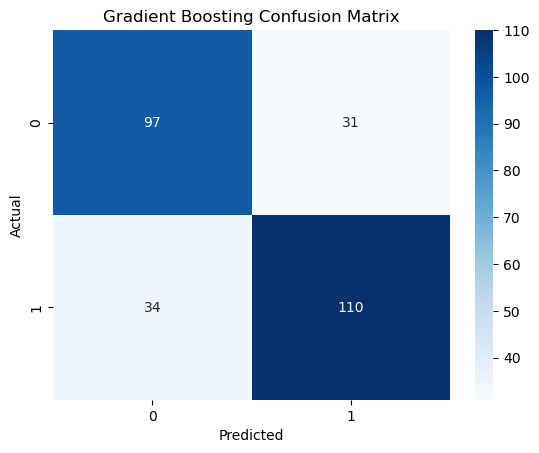

In [41]:
sns.heatmap(confusion_matrix(y_test, gb_pred),
            annot=True, fmt="d", cmap="Blues")
plt.title("Gradient Boosting Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [42]:
models = {
    "Random Forest": rf_pred,
    "AdaBoost": ada_pred,
    "Gradient Boosting": gb_pred
}

results = []

for name, pred in models.items():
    results.append([
        name,
        accuracy_score(y_test, pred),
        precision_score(y_test, pred, zero_division=0),
        recall_score(y_test, pred, zero_division=0),
        f1_score(y_test, pred, zero_division=0)
    ])

In [43]:
comparison = pd.DataFrame(
    results,
    columns=["Model", "Accuracy", "Precision", "Recall", "F1 Score"]
)

comparison.round(4)

,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.750,0.7794,0.7361,0.7571
1,AdaBoost,0.739,0.7552,0.7500,0.7526
2,Gradient Boosting,0.761,0.7801,0.7639,0.7719


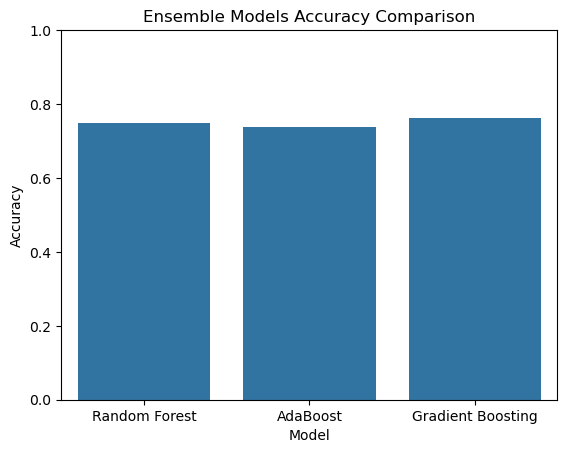

In [44]:
sns.barplot(data=comparison, x="Model", y="Accuracy")
plt.title("Ensemble Models Accuracy Comparison")
plt.ylim(0, 1)
plt.show()

In [45]:
best_model = comparison.loc[comparison["F1 Score"].idxmax()]

print("Best Model:", best_model["Model"])
print("Accuracy:", round(best_model["Accuracy"], 4))
print("F1 Score:", round(best_model["F1 Score"], 4))

Best Model: Gradient Boosting
Accuracy: 0.761
F1 Score: 0.7719


In [46]:
importance = pd.Series(
    rf.feature_importances_,
    index=X.columns
)

importance.sort_values(ascending=False)

alcohol                 0.213327
sulphates               0.122300
volatile acidity        0.108262
total sulfur dioxide    0.090982
density                 0.082465
chlorides               0.072064
fixed acidity           0.068568
pH                      0.065034
free sulfur dioxide     0.059882
citric acid             0.059873
residual sugar          0.057244
dtype: float64

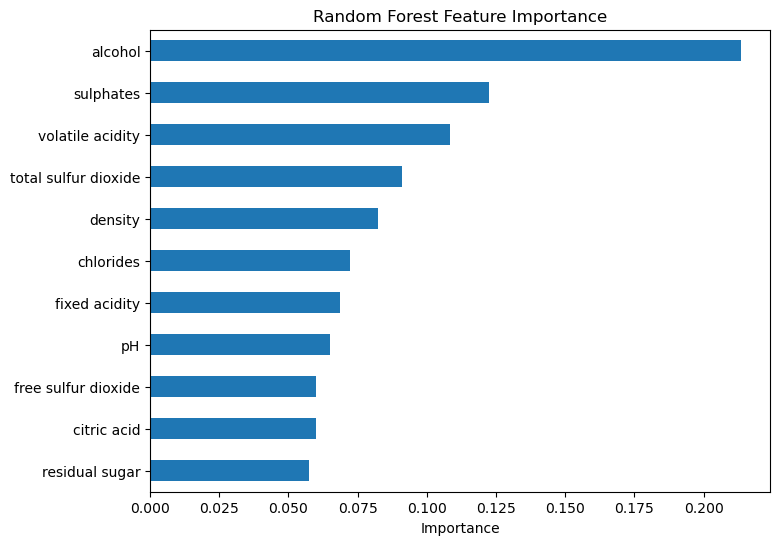

In [47]:
importance.sort_values().plot(kind="barh", figsize=(8, 6))
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.show()

In [48]:
comparison.sort_values(
    by="F1 Score",
    ascending=False
).round(4)

,Model,Accuracy,Precision,Recall,F1 Score
2,Gradient Boosting,0.761,0.7801,0.7639,0.7719
0,Random Forest,0.750,0.7794,0.7361,0.7571
1,AdaBoost,0.739,0.7552,0.7500,0.7526


In [49]:
for i, row in comparison.sort_values(
    "F1 Score", ascending=False
).reset_index(drop=True).iterrows():
    print(f"{i+1}. {row['Model']} - F1: {row['F1 Score']:.4f}")

1. Gradient Boosting - F1: 0.7719
2. Random Forest - F1: 0.7571
3. AdaBoost - F1: 0.7526


In [50]:
print("Dataset: Red Wine Quality")
print("Task: Binary Classification")
print("Models: Random Forest, AdaBoost, Gradient Boosting")
print("Best Model:", best_model["Model"])
print("Best F1 Score:", round(best_model["F1 Score"], 4))

Dataset: Red Wine Quality
Task: Binary Classification
Models: Random Forest, AdaBoost, Gradient Boosting
Best Model: Gradient Boosting
Best F1 Score: 0.7719
